# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Isaiah De Vera, William Keenan, Olympia Sauerwein

**Date:** 11/18/26

QUESTION 1

In [8]:
import pandas as pd

In [12]:
df = pd.read_csv('./heart_failure_clinical_records_dataset.csv')
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

In [13]:
print(df[["platelets", "creatinine_phosphokinase"]].mode().iloc[0])
print(df[["platelets", "creatinine_phosphokinase"]].mean())

print(df[["creatinine_phosphokinase", "serum_creatinine"]].skew())

df = df.drop(columns="time")
for c in ["creatinine_phosphokinase", "serum_creatinine"]:
    df[c] = np.arcsinh(df[c])

features = [c for c in df.columns if c != "DEATH_EVENT"]

platelets                   263358.03
creatinine_phosphokinase       582.00
Name: 0, dtype: float64
platelets                   263358.029264
creatinine_phosphokinase       581.839465
dtype: float64
creatinine_phosphokinase    4.463110
serum_creatinine            4.455996
dtype: float64


QUESTION 2

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression

seed = 100
shuffled = df.sample(frac=1, random_state=seed)
train_size = int(0.8 * len(shuffled))
train = shuffled.iloc[:train_size]
test = shuffled.iloc[train_size:]
X_train, y_train = train[features], train["DEATH_EVENT"]
X_test, y_test = test[features], test["DEATH_EVENT"]

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=200)
tree.fit(X_train, y_train)
linear = LinearRegression().fit(X_train, y_train)

tree_prediction = tree.predict_proba(X_test)[:, 1]
linear_prediction = linear.predict(X_test)

In [15]:
from sklearn.metrics import accuracy_score

majority = y_train.mode().iloc[0]
baseline_accuracy = accuracy_score(y_test, np.repeat(majority, len(y_test)))
tree_accuracy = accuracy_score(y_test, tree_prediction > 0.5)
linear_accuracy = accuracy_score(y_test, linear_prediction > 0.5)

print("Training:", len(train), "Test:", len(test))
print(f"Always {majority}: {baseline_accuracy:.1%}")
print(f"Tree: {tree_accuracy:.1%}")
print(f"Linear: {linear_accuracy:.1%}")

Training: 239 Test: 60
Always 0: 65.0%
Tree: 70.0%
Linear: 71.7%


On the seed-100 test set of 60 patients, always predicting survival was correct 65% of the time. The tree scores 70% and the linear model scores 71.7%, meaning both surpass the baseline by a few percentage points. With 60 test rows each patient is worth ~1.7 points, so the tree and linear model differ only by one patient.

QUESTION 3

In [16]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [27]:
seeds = [100, 101, 102, 103]
trees, linears, accuracies = [], [], []
tree_predictions = np.zeros((len(seeds), len(X_test)))
linear_predictions = np.zeros((len(seeds), len(X_test)))

In [28]:
for i, sd in enumerate(seeds):
    shuffled = df.sample(frac=1, random_state=sd)
    tr = shuffled.iloc[:train_size]
    te = shuffled.iloc[train_size:]
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=200)
    tree.fit(tr[features], tr["DEATH_EVENT"])
    linear = LinearRegression().fit(tr[features], tr["DEATH_EVENT"])
    trees.append(tree)
    linears.append(linear)
    tree_predictions[i] = tree.predict_proba(X_test)[:, 1]
    linear_predictions[i] = linear.predict(X_test)
    accuracies.append({
        "seed": sd,
        "tree": accuracy_score(te["DEATH_EVENT"], tree.predict(te[features])),
        "linear": accuracy_score(te["DEATH_EVENT"], linear.predict(te[features]) > 0.5),
        "always 0": accuracy_score(te["DEATH_EVENT"], np.repeat(tr["DEATH_EVENT"].mode().iloc[0], len(te))),
    })

pd.DataFrame(accuracies).round(3)

,seed,tree,linear,always 0
0,100,0.700,0.717,0.650
1,101,0.733,0.750,0.633
2,102,0.700,0.717,0.767
3,103,0.750,0.833,0.733


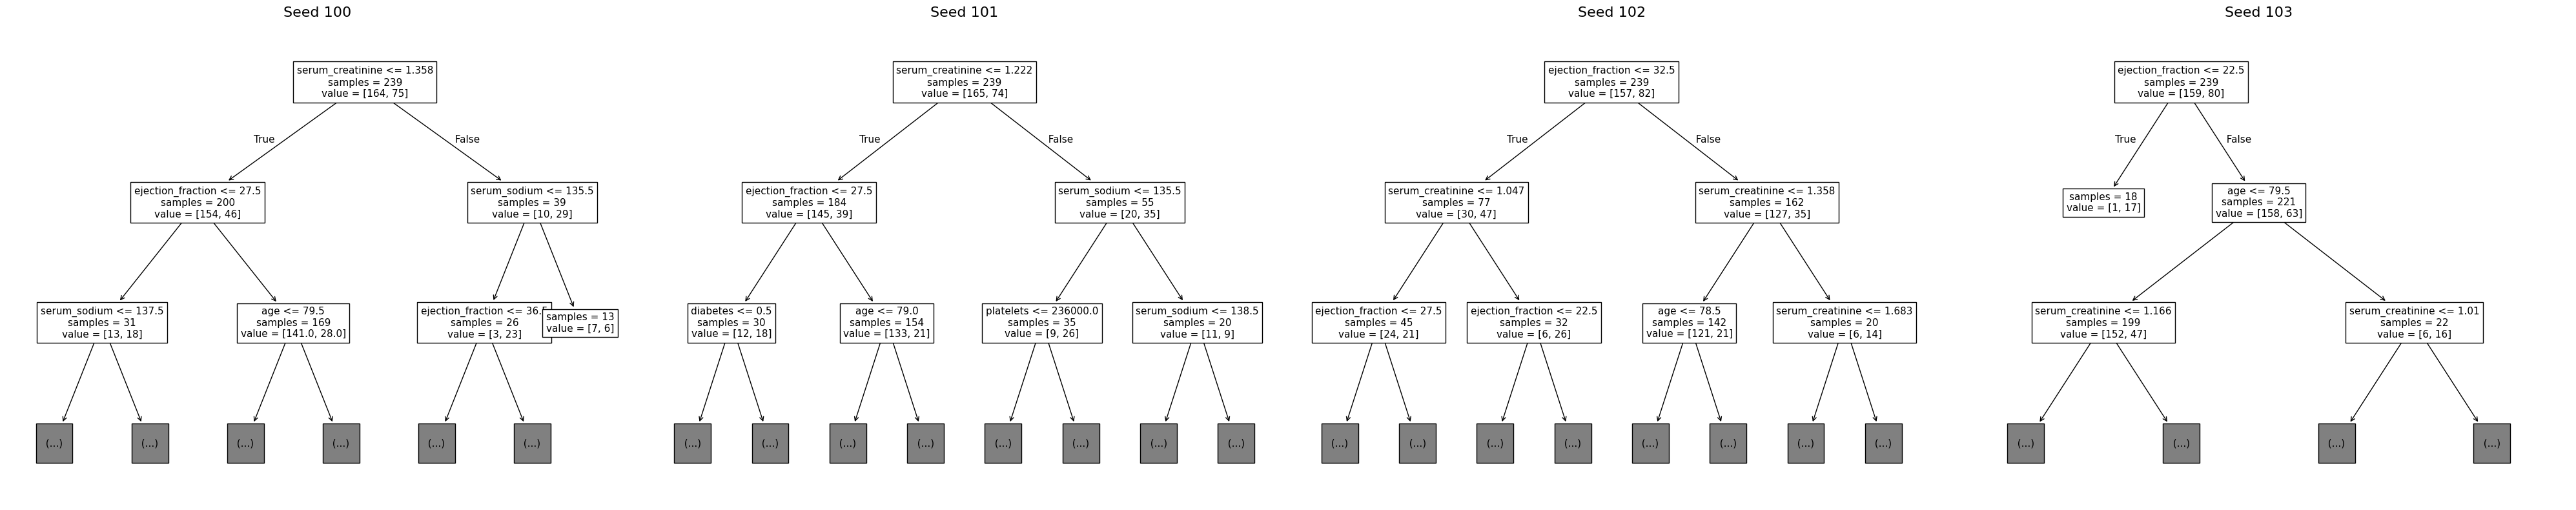

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(40, 8))
for ax, tree, sd in zip(axes, trees, seeds):
    plot_tree(tree, feature_names=features, max_depth=2, ax=ax, fontsize=11, impurity=False)
    ax.set_title(f"Seed {sd}", fontsize=16)
plt.tight_layout()
plt.show()

In [30]:
pd.DataFrame({sd: m.coef_ for sd, m in zip(seeds, linears)}, index=features).round(3)

,100,101,102,103
age,0.009,0.006,0.008,0.009
anaemia,0.085,0.071,0.081,0.042
creatinine_phosphokinase,0.041,0.019,0.049,0.039
diabetes,0.065,0.022,0.002,0.007
ejection_fraction,-0.009,-0.011,-0.011,-0.009
high_blood_pressure,0.074,0.110,0.113,0.071
platelets,-0.000,-0.000,0.000,-0.000
serum_creatinine,0.394,0.372,0.275,0.326
serum_sodium,-0.008,-0.007,-0.009,-0.006
sex,-0.051,-0.070,-0.070,-0.106


The trees notably differ for each seed. Seeds 100 and 101 split on serum_creatinine first at different cutoffs, while seeds 102 and 103 split on ejection_fraction first, and seed 103 has a single leaf on one side where the other three continue splitting. Below the root, each tree uses a different combination of features including age, platelets, serum_sodium, and diabetes. The linear coefficients are much more similar among the four different seeds. serum_creatinine remains the largest across the seeds and ejection_fraction is relatively constant with most signs agreeing. Some of the weaker variables vary more, such as diabetes moving from 0.002 to 0.065 or smoking changing sign. Overall, the appearance of the trees changes a lot where the linear model changes much less.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [1]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]